# WarpSpeed plans, checked exactly

WarpSpeed (NVIDIA CCCL) describes a warp-specialized kernel as **squads** (contiguous groups of warps with one job)
that hand **staged shared-memory resources** to each other through **phases**. Every quantity a plan implies can be
derived, so a plan can be checked before it is compiled:

$$
\text{arrivals}(\text{phase}) = 32 \sum_{s \in \text{owners}} \text{warps}_s, \qquad
\text{smem} = \sum_{r} \text{stages}_r\, \text{stride}_r \;+\; 8 \sum_{r} \text{phases}_r\, \text{stages}_r ,
$$

$$
\text{register cap} = \min\!\Big(255,\ \Big\lfloor \frac{65536}{128\,\lceil \text{warps}/4 \rceil\, \text{CTAs per SM}} \Big\rfloor_8 \Big).
$$

Here is the large-batch build of our H200 MoE kernel: four MMA warpgroups fed by a weight-producer warp and an
activation-producer warp through two TMA rings.

In [1]:
import sys; sys.path[:0] = ['..', '.']
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import xcalibur as xc
from style import C, SEQ, MUTED, INK, DATA, save, note
plan = xc.plan_of([("mma", 16), ("w_load", 1), ("x_load", 1)],
                  [("w_ring", 3, 36864, [("w_load", 36864), ("mma", None)]),
                   ("x_ring", 3, 32768, [("x_load", 32768), ("mma", None)])])
r = xc.warpspeed_check(**plan)
print("pass:", r["pass"], "| register cap:", r["registers"]["launch_cap"], "| mbarriers:", r["mbarriers"],
      "| shared memory:", r["smem"]["total_bytes"], "of", r["smem"]["cta_limit"])

pass: True | register cap: 96 | mbarriers: 12 | shared memory: 208992 of 232448


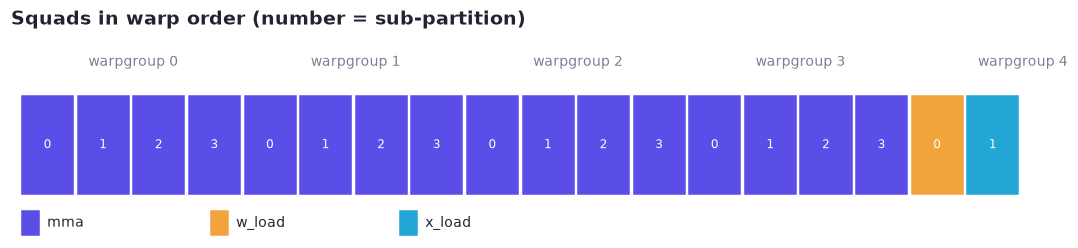

In [2]:
fig, ax = plt.subplots(figsize=(12, 2.4))
col = {"mma": C["ours"], "w_load": C["accent"], "x_load": C["cyan"]}
for s in r["squads"]:
    for wrp in range(s["warp_begin"], s["warp_end"]):
        ax.add_patch(plt.Rectangle((wrp, 0), 0.92, 0.92, color=col[s["name"]]))
        ax.text(wrp + 0.46, 0.46, f"{wrp % 4}", ha="center", va="center", color="white", fontsize=8)
for g in range(5):
    ax.text(g * 4 + 2, 1.2, f"warpgroup {g}", ha="center", color=MUTED, fontsize=9)
ax.set_xlim(-0.2, 18.2); ax.set_ylim(-0.4, 1.5); ax.axis("off")
for i, (n, cc) in enumerate(col.items()):
    ax.add_patch(plt.Rectangle((i * 3.4, -0.38), 0.3, 0.22, color=cc)); ax.text(i * 3.4 + 0.45, -0.27, n, va="center", fontsize=9)
ax.set_title("Squads in warp order (number = sub-partition)")
save(fig, "ws_squads"); plt.show()

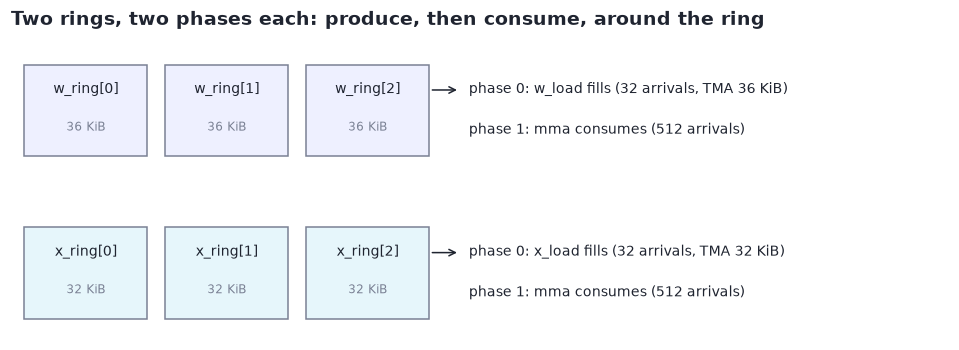

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for row, res in enumerate(r["resources"]):
    y = 1.6 - row * 1.6
    for st in range(res["stages"]):
        x = st * 3.2
        ax.add_patch(plt.Rectangle((x, y), 2.8, 0.9, fc="#eef0ff" if row == 0 else "#e6f6fb", ec=MUTED))
        ax.text(x + 1.4, y + 0.62, f"{res['name']}[{st}]", ha="center", fontsize=9)
        ax.text(x + 1.4, y + 0.25, f"{res['stride_bytes'] // 1024} KiB", ha="center", fontsize=8, color=MUTED)
    p0, p1 = res["phases"]
    ax.annotate("", xy=(9.9, y + 0.65), xytext=(9.2, y + 0.65), arrowprops=dict(arrowstyle="->", color=INK))
    ax.text(10.1, y + 0.62, f"phase 0: {p0['owners'][0]} fills ({p0['arrival_count']} arrivals, TMA {p0.get('tx_bytes', 0) // 1024} KiB)", fontsize=9)
    ax.text(10.1, y + 0.22, f"phase 1: {p1['owners'][0]} consumes ({p1['arrival_count']} arrivals)", fontsize=9)
ax.set_xlim(-0.3, 21); ax.set_ylim(-0.2, 2.8); ax.axis("off")
ax.set_title("Two rings, two phases each: produce, then consume, around the ring")
save(fig, "ws_rings"); plt.show()

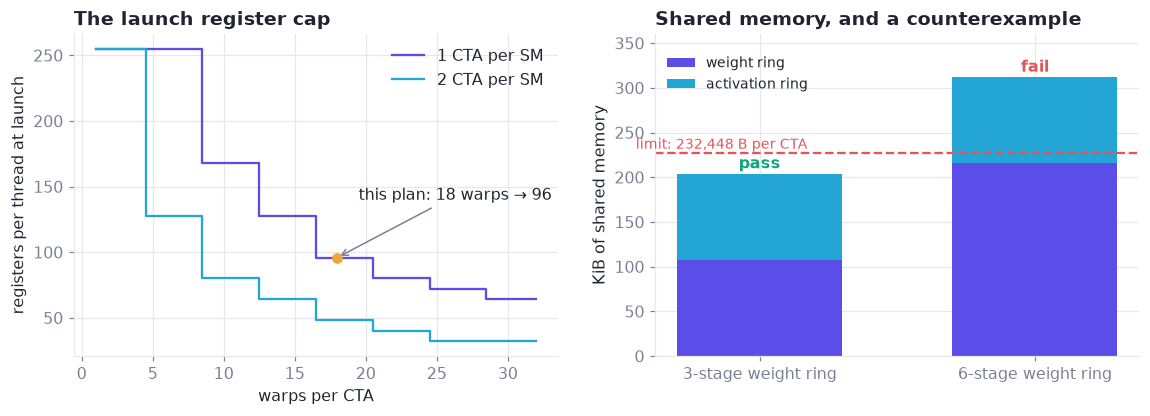

counterexample: 319632 B of shared memory exceed 232448 B per CTA


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
ws = np.arange(1, 33)
for cps, cc in ((1, C["ours"]), (2, C["cyan"])):
    axes[0].step(ws, [xc.launch_register_cap(xc.H200, w, cps) for w in ws], where="mid", color=cc, label=f"{cps} CTA per SM")
axes[0].scatter([18], [96], color=C["accent"], zorder=5); axes[0].annotate("this plan: 18 warps → 96", (18, 96), (19.5, 140), arrowprops=dict(arrowstyle="->", color=MUTED))
axes[0].set_xlabel("warps per CTA"); axes[0].set_ylabel("registers per thread at launch"); axes[0].legend()
axes[0].set_title("The launch register cap")
deep = dict(plan); deep["resources"] = [dict(plan["resources"][0], stages=6), plan["resources"][1]]
bad = xc.warpspeed_check(**deep)
for i, (name, res) in enumerate((("3-stage weight ring", r), ("6-stage weight ring", bad))):
    w = res["resources"][0]["bytes"]; x = res["resources"][1]["bytes"]
    axes[1].bar(i, w / 1024, 0.6, color=C["ours"], label="weight ring" if i == 0 else None)
    axes[1].bar(i, x / 1024, 0.6, bottom=w / 1024, color=C["cyan"], label="activation ring" if i == 0 else None)
    axes[1].text(i, (res["smem"]["total_bytes"]) / 1024 + 6, "pass" if res["pass"] else "fail", ha="center",
                 color=C["good"] if res["pass"] else C["bad"], fontweight="bold")
axes[1].axhline(r["smem"]["cta_limit"] / 1024, color=C["bad"], ls="--")
axes[1].text(-0.45, r["smem"]["cta_limit"] / 1024 + 5, "limit: 232,448 B per CTA", color=C["bad"], fontsize=9)
axes[1].set_ylim(0, 360); axes[1].legend(loc="upper left", fontsize=9, bbox_to_anchor=(0, 0.97))
axes[1].set_xticks([0, 1], ["3-stage weight ring", "6-stage weight ring"]); axes[1].set_ylabel("KiB of shared memory")
axes[1].set_title("Shared memory, and a counterexample")
save(fig, "ws_limits"); plt.show()
print("counterexample:", bad["counterexample"]["message"])